# RaphIA · Detector de hojas YOLOv8 (n, s y m)

**Qué hace este notebook:** entrena YOLOv8n, YOLOv8s y YOLOv8m con la misma configuración, los evalúa con las imágenes de prueba, exporta el elegido (YOLOv8m) a ONNX y genera las figuras del paper en inglés.

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU`.

Todo lo importante se copia a tu Drive apenas se genera, para no perderlo si Colab se desconecta.

### 1. Instalación de librerías

In [1]:
!pip install -q ultralytics roboflow onnx onnxslim onnxruntime

### 2. Verificación de la GPU

In [2]:
!nvidia-smi
import torch, ultralytics
print("Ultralytics:", ultralytics.__version__)
print("Torch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Mon Nov 16 00:41:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P0             45W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

### 3. Montar Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 4. Carpetas
- `CARPETA_DRIVE`: donde se guardan los resultados (no se pierde).
- `CARPETA_RUNS`: carpeta temporal de Colab donde YOLO entrena (se borra al cerrar la sesión).

In [4]:
import os

RAIZ = "/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)"
CARPETA_DRIVE = f"{RAIZ}/Modelos/Resultados/01_YOLO"
CARPETA_RUNS = "/content/runs_raphia"

os.makedirs(CARPETA_DRIVE, exist_ok=True)
print("Resultados en:", CARPETA_DRIVE)

Resultados en: /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO


### 5. Descarga del dataset (Roboflow)

In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="Se5StYMd0hO7BnTBbmzK")
project = rf.workspace("upc-og4hi").project("potato-leaf-zt8ri")
version = project.version(12)
dataset = version.download("yolov8", location="/content/Potato-leaf-11")



DATA_YAML = "/content/Potato-leaf-11/data.yaml"
print(open(DATA_YAML).read())

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/Potato-leaf-11 in yolov8:: 100%|██████████| 15741/15741 [00:01<00:00, 7945.24it/s] 


names:
- potato_leaf
nc: 1
roboflow:
  license: CC BY 4.0
  project: potato-leaf-zt8ri
  url: https://universe.roboflow.com/upc-og4hi/potato-leaf-zt8ri/dataset/12
  version: 12
  workspace: upc-og4hi
test: ../test/images
train: ../train/images
val: ../valid/images



### 6. Conteo del dataset
Para la tabla de particiones del paper. `train` ya incluye las copias aumentadas por Roboflow (×3).

In [6]:
import glob

def contar(etapa):
    etiquetas = glob.glob(f"/content/Potato-leaf-11/{etapa}/labels/*.txt")
    hojas = 0
    imagenes_fondo = 0
    for archivo in etiquetas:
        n = len([linea for linea in open(archivo) if linea.strip()])
        hojas += n
        if n == 0:
            imagenes_fondo += 1
    return {"etapa": etapa, "imagenes": len(etiquetas), "hojas_anotadas": hojas, "imagenes_sin_hojas": imagenes_fondo}

In [7]:
import pandas as pd

conteo = pd.DataFrame([contar("train"), contar("valid"), contar("test")])
conteo.to_csv(f"{CARPETA_DRIVE}/conteo_dataset.csv", index=False)
conteo

,etapa,imagenes,hojas_anotadas,imagenes_sin_hojas
0,train,6885,8161,2516
1,valid,492,482,224
2,test,491,507,204


### 7. Configuración del entrenamiento (igual que en el paper)
`patience=100` con 50 épocas significa que **no hay early stopping**: siempre se entrenan las 50 épocas y YOLO guarda el mejor modelo (`best.pt`).

In [8]:
CONFIG = dict(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    optimizer="auto",
    lr0=0.001,
    weight_decay=0.0005,
    patience=100,
    seed=0,
    deterministic=True,
    device=0,
    project=CARPETA_RUNS,
    exist_ok=True,
)

### 8. Entrenamiento YOLOv8n

In [9]:
from ultralytics import YOLO
import time, shutil

inicio = time.time()
YOLO("yolov8n.pt").train(name="yolov8n", **CONFIG)
horas_n = round((time.time() - inicio) / 3600, 2)

shutil.copy(f"{CARPETA_RUNS}/yolov8n/weights/best.pt", f"{CARPETA_DRIVE}/yolov8n_best.pt")
shutil.copy(f"{CARPETA_RUNS}/yolov8n/results.csv", f"{CARPETA_DRIVE}/yolov8n_results.csv")
print("YOLOv8n listo en", horas_n, "horas")

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Potato-leaf-11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n, nbs=64, nms=None, opset=None, op

### 9. Entrenamiento YOLOv8s

In [10]:
inicio = time.time()
YOLO("yolov8s.pt").train(name="yolov8s", **CONFIG)
horas_s = round((time.time() - inicio) / 3600, 2)

shutil.copy(f"{CARPETA_RUNS}/yolov8s/weights/best.pt", f"{CARPETA_DRIVE}/yolov8s_best.pt")
shutil.copy(f"{CARPETA_RUNS}/yolov8s/results.csv", f"{CARPETA_DRIVE}/yolov8s_results.csv")
print("YOLOv8s listo en", horas_s, "horas")

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Potato-leaf-11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s, nbs=64, nms=None, opset=None, op

### 10. Entrenamiento YOLOv8m

In [11]:
inicio = time.time()
YOLO("yolov8m.pt").train(name="yolov8m", **CONFIG)
horas_m = round((time.time() - inicio) / 3600, 2)

shutil.copy(f"{CARPETA_RUNS}/yolov8m/weights/best.pt", f"{CARPETA_DRIVE}/yolov8m_best.pt")
shutil.copy(f"{CARPETA_RUNS}/yolov8m/results.csv", f"{CARPETA_DRIVE}/yolov8m_results.csv")
print("YOLOv8m listo en", horas_m, "horas")

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Potato-leaf-11/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

### 11. Evaluación en el conjunto de prueba (test)
Se cargan los pesos desde Drive, así esta parte funciona aunque la sesión se haya reiniciado.

In [12]:
def evaluar(nombre):
    modelo = YOLO(f"{CARPETA_DRIVE}/{nombre}_best.pt")
    r = modelo.val(data=DATA_YAML, split="test", plots=False, verbose=False)
    p, rec = r.box.mp, r.box.mr
    return {
        "modelo": nombre,
        "parametros_M": round(sum(x.numel() for x in modelo.model.parameters()) / 1e6, 2),
        "precision": round(p, 3),
        "recall": round(rec, 3),
        "F1": round(2 * p * rec / (p + rec), 3),
        "mAP50": round(r.box.map50, 3),
        "mAP50_95": round(r.box.map, 3),
    }

In [13]:
test_n = evaluar("yolov8n")
test_n

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1841.2±557.9 MB/s, size: 59.6 KB)
val: Scanning /content/Potato-leaf-11/test/labels... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 1.4Kit/s 0.3s
val: New cache created: /content/Potato-leaf-11/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 15.3it/s 2.0s
                   all        491        507      0.871      0.905      0.959      0.931
Speed: 0.6ms preprocess, 0.9ms inference, 0.0ms loss, 0.6ms postprocess per image


{'modelo': 'yolov8n',
 'parametros_M': 3.14,
 'precision': np.float64(0.871),
 'recall': np.float64(0.905),
 'F1': np.float64(0.888),
 'mAP50': np.float64(0.959),
 'mAP50_95': np.float64(0.931)}

In [14]:
test_s = evaluar("yolov8s")
test_s

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1490.1±616.0 MB/s, size: 59.8 KB)
val: Scanning /content/Potato-leaf-11/test/labels.cache... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 205.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 13.8it/s 2.2s
                   all        491        507       0.92      0.872      0.959      0.932
Speed: 0.6ms preprocess, 1.3ms inference, 0.0ms loss, 0.7ms postprocess per image


{'modelo': 'yolov8s',
 'parametros_M': 11.14,
 'precision': np.float64(0.92),
 'recall': np.float64(0.872),
 'F1': np.float64(0.895),
 'mAP50': np.float64(0.959),
 'mAP50_95': np.float64(0.932)}

In [15]:
test_m = evaluar("yolov8m")
test_m

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1945.6±680.9 MB/s, size: 74.4 KB)
val: Scanning /content/Potato-leaf-11/test/labels.cache... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 158.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 11.2it/s 2.8s
                   all        491        507      0.901      0.905      0.961      0.936
Speed: 0.6ms preprocess, 2.4ms inference, 0.0ms loss, 0.6ms postprocess per image


{'modelo': 'yolov8m',
 'parametros_M': 25.86,
 'precision': np.float64(0.901),
 'recall': np.float64(0.905),
 'F1': np.float64(0.903),
 'mAP50': np.float64(0.961),
 'mAP50_95': np.float64(0.936)}

### 12. Métricas de validación de YOLOv8m (fila "Validation" de la tabla del paper)

In [16]:
r_val = YOLO(f"{CARPETA_DRIVE}/yolov8m_best.pt").val(data=DATA_YAML, split="val", plots=False, verbose=False)
val_m = {"precision": round(r_val.box.mp, 3), "recall": round(r_val.box.mr, 3), "mAP50": round(r_val.box.map50, 3)}
val_m

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2027.4±893.2 MB/s, size: 73.1 KB)
val: Scanning /content/Potato-leaf-11/valid/labels.cache... 492 images, 224 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 492/492 187.6Mit/s 0.0s
val: /content/Potato-leaf-11/valid/images/20230802_115927_jpg.rf.a973e393f09775103f89d773420c2726.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 11.2it/s 2.8s
                   all        492        481      0.882      0.875      0.949      0.929
Speed: 0.6ms preprocess, 2.4ms inference, 0.0ms loss, 0.6ms postprocess per image


{'precision': np.float64(0.882),
 'recall': np.float64(0.875),
 'mAP50': np.float64(0.949)}

### 13. Exportar a ONNX (FP32, sin cuantización)

In [17]:
onnx_n = YOLO(f"{CARPETA_DRIVE}/yolov8n_best.pt").export(format="onnx", imgsz=640, opset=17, half=False, simplify=True)

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8n_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.2s, saved as '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8n_best.onnx' (12.2 MB)

Export complete (1.4s)
Results saved to /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8n_best.onnx
Predict:         yolo pred

In [18]:
onnx_s = YOLO(f"{CARPETA_DRIVE}/yolov8s_best.pt").export(format="onnx", imgsz=640, opset=17, half=False, simplify=True)


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8s_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (21.5 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.4s, saved as '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8s_best.onnx' (42.7 MB)

Export complete (1.6s)
Results saved to /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8s_best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8s_best.onnx imgsz=640 
Validate:

In [19]:
onnx_m = YOLO(f"{CARPETA_DRIVE}/yolov8m_best.pt").export(format="onnx", imgsz=640, opset=17, half=False, simplify=True)


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (49.6 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.8s, saved as '/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx' (98.8 MB)

Export complete (3.2s)
Results saved to /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx
Predict:         yolo predict task=detect model=/content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx imgsz=640 
Validate:

### 14. ¿El ONNX da lo mismo que PyTorch?
Se comparan **en las mismas condiciones**: imágenes de 640×640 cuadradas, de una en una (`batch=1`, `rect=False`). Si los números coinciden, el ONNX que va a Cloud Run es fiel al modelo entrenado.

In [20]:
r_pt = YOLO(f"{CARPETA_DRIVE}/yolov8m_best.pt").val(data=DATA_YAML, split="test", batch=1, rect=False, plots=False, verbose=False)
print("PyTorch  -> P:", round(r_pt.box.mp, 3), "R:", round(r_pt.box.mr, 3), "mAP50:", round(r_pt.box.map50, 3))

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 92 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1437.6±478.6 MB/s, size: 72.7 KB)
val: Scanning /content/Potato-leaf-11/test/labels.cache... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 137.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 491/491 65.5it/s 7.5s
                   all        491        507      0.893      0.843      0.939      0.918
Speed: 0.9ms preprocess, 9.9ms inference, 0.0ms loss, 0.9ms postprocess per image
PyTorch  -> P: 0.893 R: 0.843 mAP50: 0.939


In [21]:
r_onnx = YOLO(f"{CARPETA_DRIVE}/yolov8m_best.onnx", task="detect").val(data=DATA_YAML, split="test", batch=1, device="cpu", plots=False, verbose=False)
print("ONNX     -> P:", round(r_onnx.box.mp, 3), "R:", round(r_onnx.box.mr, 3), "mAP50:", round(r_onnx.box.map50, 3))

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Loading /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1091.7±302.6 MB/s, size: 54.6 KB)
val: Scanning /content/Potato-leaf-11/test/labels.cache... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 171.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 491/491 5.2it/s 1:34
                   all        491        507      0.893      0.843      0.939      0.917
Speed: 13.9ms preprocess, 163.5ms inference, 0.0ms loss, 3.0ms postprocess per image
ONNX     -> P: 0.893 R: 0.843 mAP50: 0.939


### 15. Matriz de confusión con el umbral del sistema (conf = 0.5)
Tu API (`main.py`) usa `conf=0.50`. Con ese mismo umbral se cuentan las hojas bien detectadas, las omitidas y las detecciones falsas.

In [23]:
r_cm = YOLO(f"{CARPETA_DRIVE}/yolov8m_best.onnx", task="detect").val(data=DATA_YAML, split="test", conf=0.5, batch=1, device="cpu", plots=True, verbose=False)
matriz = r_cm.confusion_matrix.matrix.astype(int)   # filas = predicho, columnas = real
print("Hojas detectadas correctamente:", matriz[0, 0])
print("Hojas no detectadas (falsos negativos):", matriz[1, 0])
print("Detecciones sobre fondo (falsos positivos):", matriz[0, 1])

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
Loading /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO/yolov8m_best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Setting batch=1 input of shape (1, 3, 640, 640)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1787.9±490.9 MB/s, size: 60.3 KB)
val: Scanning /content/Potato-leaf-11/test/labels.cache... 491 images, 204 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 491/491 187.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 491/491 5.2it/s 1:35
                   all        491        507      0.893      0.843      0.899      0.881
Speed: 14.1ms preprocess, 165.5ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/runs/detect/val-8
Hojas detectadas correctamente: 469
Hojas no detectadas (falsos negativos): 38
Detecciones sobre fondo (fal

### 16. Latencia en CPU (4 hilos, como Cloud Run)
Se mide solo la inferencia del modelo con 50 imágenes de prueba.

In [24]:
import onnxruntime as ort
import numpy as np
import cv2

def latencia_ms(ruta_onnx, n_imagenes=50):
    opciones = ort.SessionOptions()
    opciones.intra_op_num_threads = 4
    sesion = ort.InferenceSession(ruta_onnx, opciones, providers=["CPUExecutionProvider"])
    entrada = sesion.get_inputs()[0].name
    tiempos = []
    for ruta in sorted(glob.glob("/content/Potato-leaf-11/test/images/*"))[:n_imagenes]:
        img = cv2.resize(cv2.imread(ruta), (640, 640))[:, :, ::-1] / 255.0
        x = img.transpose(2, 0, 1)[None].astype(np.float32)
        inicio = time.perf_counter()
        sesion.run(None, {entrada: x})
        tiempos.append((time.perf_counter() - inicio) * 1000)
    return round(float(np.mean(tiempos[5:])), 1)   # se descartan 5 de calentamiento

In [25]:
lat_n = latencia_ms(f"{CARPETA_DRIVE}/yolov8n_best.onnx")
lat_s = latencia_ms(f"{CARPETA_DRIVE}/yolov8s_best.onnx")
lat_m = latencia_ms(f"{CARPETA_DRIVE}/yolov8m_best.onnx")
print("CPU:", os.popen("lscpu | grep 'Model name'").read().strip())
print("ms por imagen -> n:", lat_n, "| s:", lat_s, "| m:", lat_m)

CPU: Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
ms por imagen -> n: 40.3 | s: 86.2 | m: 204.8


### 17. Tabla comparativa n / s / m
Si la sesión se reinició después de entrenar, las variables `horas_n`, `horas_s` y `horas_m` se pierden: escríbelas a mano (por ejemplo `horas_n = 0.38`) antes de correr esta celda.

In [26]:
test_n["horas_entrenamiento"], test_s["horas_entrenamiento"], test_m["horas_entrenamiento"] = horas_n, horas_s, horas_m
test_n["cpu_ms"], test_s["cpu_ms"], test_m["cpu_ms"] = lat_n, lat_s, lat_m

tabla = pd.DataFrame([test_n, test_s, test_m])
tabla.to_csv(f"{CARPETA_DRIVE}/comparacion_yolo.csv", index=False)
tabla

,modelo,parametros_M,precision,recall,F1,mAP50,mAP50_95,horas_entrenamiento,cpu_ms
0,yolov8n,3.14,0.871,0.905,0.888,0.959,0.931,0.41,40.3
1,yolov8s,11.14,0.920,0.872,0.895,0.959,0.932,0.42,86.2
2,yolov8m,25.86,0.901,0.905,0.903,0.961,0.936,0.53,204.8


### 18. Figura: curva de pérdida de YOLOv8m
Se omite la época 1 porque la pérdida de validación inicial es muy alta y aplasta el gráfico.

In [35]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "serif", "font.size": 7})

curvas = pd.read_csv(f"{CARPETA_DRIVE}/yolov8m_results.csv")
curvas.columns = curvas.columns.str.strip()
curvas = curvas[curvas["epoch"] > 1]

perdida_train = curvas["train/box_loss"] + curvas["train/cls_loss"] + curvas["train/dfl_loss"]
perdida_val = curvas["val/box_loss"] + curvas["val/cls_loss"] + curvas["val/dfl_loss"]

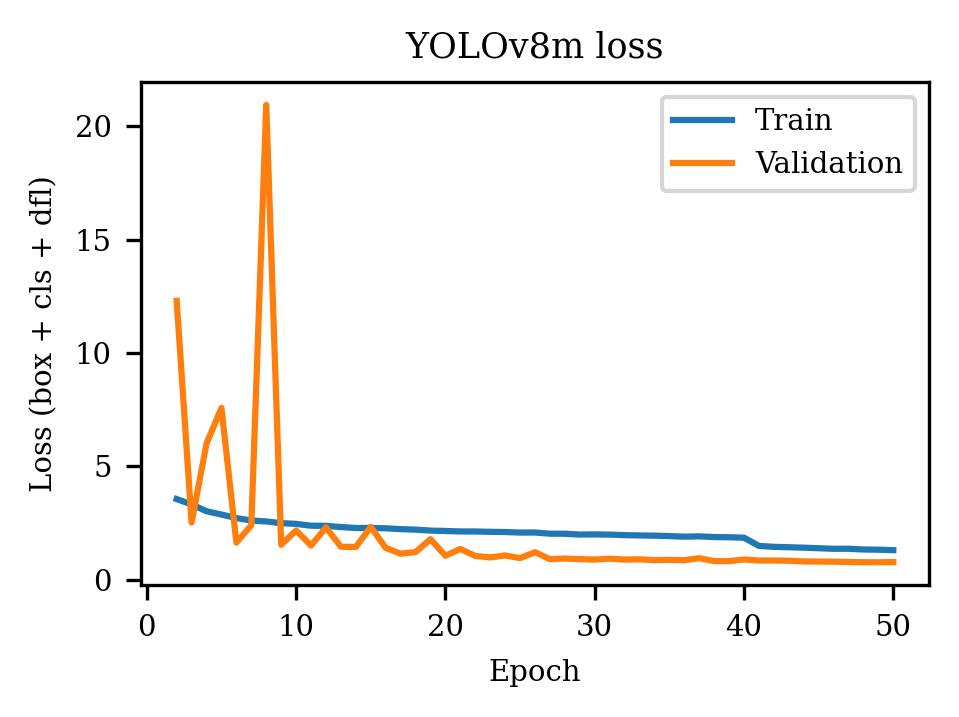

In [36]:
fig, ax = plt.subplots(figsize=(3.3, 2.4), dpi=300)
ax.plot(curvas["epoch"], perdida_train, label="Train")
ax.plot(curvas["epoch"], perdida_val, label="Validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (box + cls + dfl)")
ax.set_title("YOLOv8m loss")
ax.legend()
fig.tight_layout()
fig.savefig(f"{CARPETA_DRIVE}/fig_yolov8m_loss.png", bbox_inches="tight")
plt.show()

### 19. Figura: mAP@0.5 de validación por época

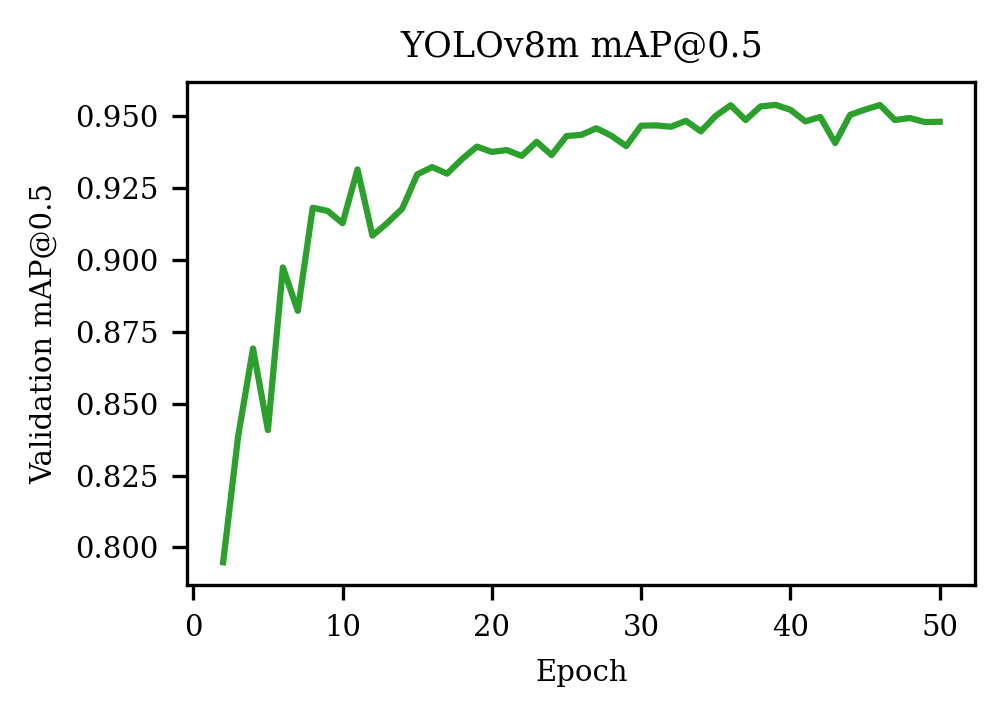

In [37]:
fig, ax = plt.subplots(figsize=(3.3, 2.4), dpi=300)
ax.plot(curvas["epoch"], curvas["metrics/mAP50(B)"], color="tab:green")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation mAP@0.5")
ax.set_title("YOLOv8m mAP@0.5")
fig.tight_layout()
fig.savefig(f"{CARPETA_DRIVE}/fig_yolov8m_map.png", bbox_inches="tight")
plt.show()

### 20. Figura: matriz de confusión (conf = 0.5)

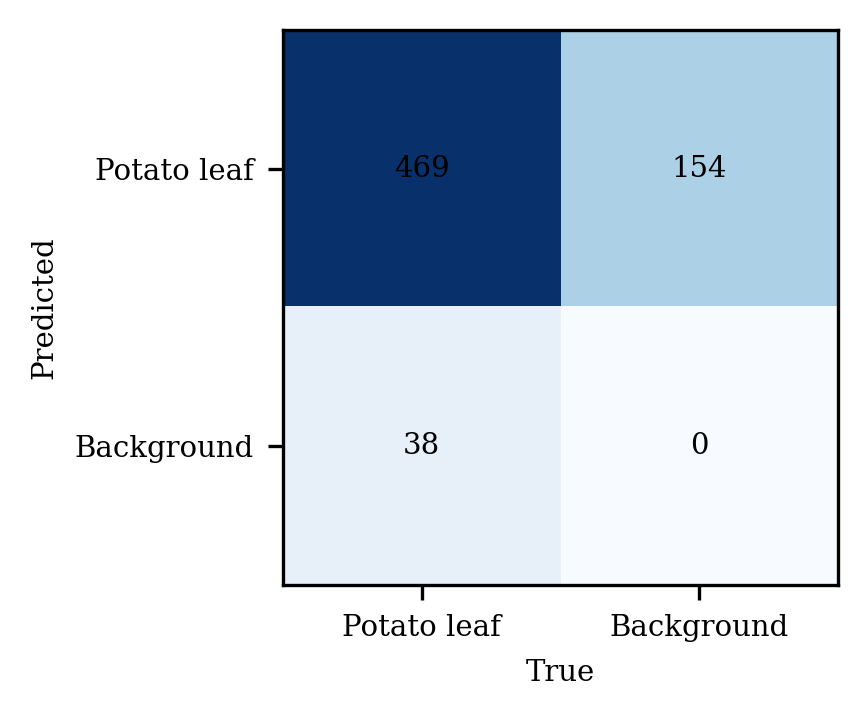

In [38]:
etiquetas = ["Potato leaf", "Background"]
fig, ax = plt.subplots(figsize=(3.0, 2.4), dpi=300)
ax.imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, matriz[i, j], ha="center", va="center")
ax.set_xticks([0, 1]); ax.set_xticklabels(etiquetas)
ax.set_yticks([0, 1]); ax.set_yticklabels(etiquetas)
ax.set_xlabel("True")
ax.set_ylabel("Predicted")
fig.tight_layout()
fig.savefig(f"{CARPETA_DRIVE}/fig_yolov8m_confusion_matrix.png", bbox_inches="tight")
plt.show()

### 21. Figura: comparación de variantes (exactitud frente a velocidad)

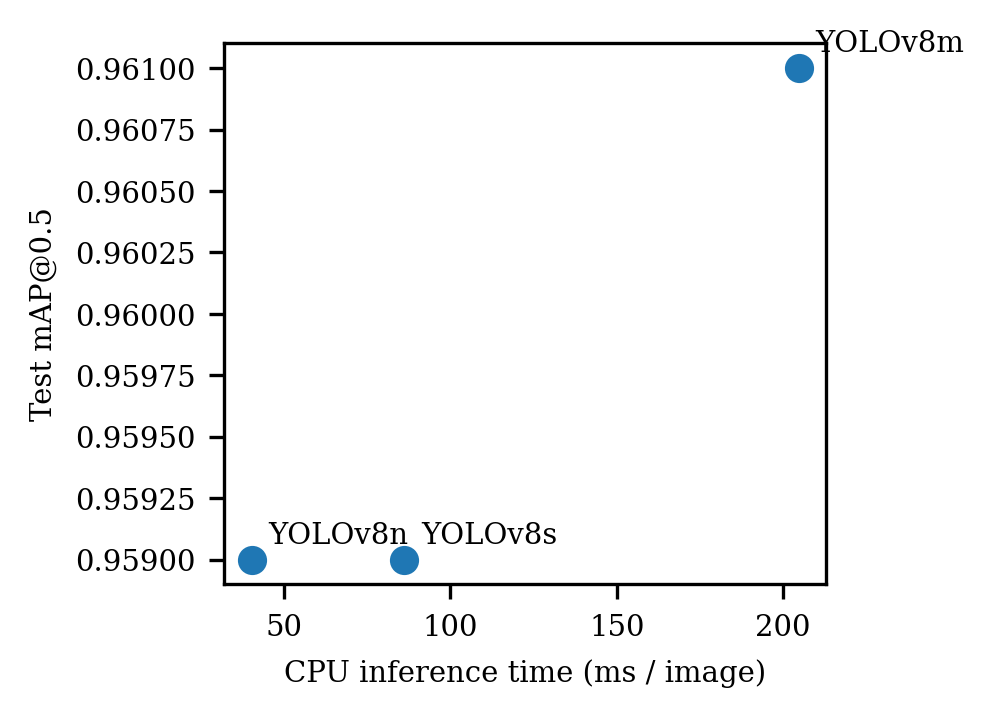

In [39]:
fig, ax = plt.subplots(figsize=(3.3, 2.4), dpi=300)
ax.scatter(tabla["cpu_ms"], tabla["mAP50"])
for _, fila in tabla.iterrows():
    ax.annotate(fila["modelo"].replace("yolo", "YOLO"), (fila["cpu_ms"], fila["mAP50"]), textcoords="offset points", xytext=(4, 4))
ax.set_xlabel("CPU inference time (ms / image)")
ax.set_ylabel("Test mAP@0.5")
fig.tight_layout()
fig.savefig(f"{CARPETA_DRIVE}/fig_yolo_variants.png", bbox_inches="tight")
plt.show()

### 22. Guardar el resumen
Pásame este archivo (`resumen_yolo.json`) junto con `comparacion_yolo.csv`, `conteo_dataset.csv` y `yolov8m_results.csv`.

In [40]:
import json

resumen = {
    "gpu": torch.cuda.get_device_name(0),
    "ultralytics": ultralytics.__version__,
    "configuracion": {k: v for k, v in CONFIG.items() if k not in ("data", "project")},
    "onnx": {"opset": 17, "precision": "FP32", "cuantizacion": "ninguna"},
    "conteo_dataset": conteo.to_dict(orient="records"),
    "comparacion": tabla.to_dict(orient="records"),
    "validacion_yolov8m": val_m,
    "pytorch_vs_onnx": {"pytorch": [r_pt.box.mp, r_pt.box.mr, r_pt.box.map50], "onnx": [r_onnx.box.mp, r_onnx.box.mr, r_onnx.box.map50]},
    "matriz_conf_050_pred_x_real": matriz.tolist(),
}
json.dump(resumen, open(f"{CARPETA_DRIVE}/resumen_yolo.json", "w"), indent=2, default=float)
print("Guardado en", CARPETA_DRIVE)

Guardado en /content/drive/MyDrive/Paper VISAPP 2027 (Modelos)/Modelos/Resultados/01_YOLO
